# EDA 02: Do concerts move Bluebikes demand?

Extends the pilot (Red Sox night games vs non-game days near Fenway) to **concert nights** at
**MGM Music Hall** (next to the same Fenway stations) and **TD Garden** (North Station).

- **Bluebikes trips:** May–Oct 2024 (public monthly files, `data/raw/bluebikes/`). Trips under 1 minute or over 24 hours are dropped, as in the pilot.
- **Stations:** within 500 m of each venue.
- **Concert nights:** our event table (`data/processed/nonsports_events.csv`).
- **Clean nights only:** both groups exclude days with a home game at the same site (Red Sox for MGM; Celtics or Bruins for TD Garden) or an event at a venue sharing the same stations (Fenway Park concerts and House of Blues for MGM; Big Night Live for TD Garden). No-event nights also exclude anything Do617 lists at our venue (comedy, family shows).
- **Comparison:** nights with no event at that venue, **reweighted to the same month and weekday-type mix** (Mon–Thu / Fri–Sat / Sun) as the concert nights. A weekday-only match left MGM concert days higher *all day*, a seasonal confound, not a concert effect.
- **Bands:** ±1.96 standard errors of the concert-night mean.

Descriptive only: no weather adjustment, and smaller events we can't see may still add noise.

In [1]:
import glob, json, math, re, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "eda" else Path.cwd()
RAW, FIG = ROOT / "data" / "raw", ROOT / "eda" / "figures"
NAVY, MUTED, GRID = "#0B2240", "#5b6577", "#e3e7ee"
EVENT, BASE = "#c8102e", "#2a78d6"   # deck red = event nights, blue = comparison (validated pair)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRID,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlecolor": NAVY, "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "text.color": NAVY, "legend.frameon": False,
})

cols = ["started_at", "ended_at", "start_station_name", "start_lat", "start_lng", "end_station_name"]
frames = []
for z in sorted(glob.glob(str(RAW / "bluebikes" / "2024*-bluebikes-tripdata.zip"))):
    with zipfile.ZipFile(z) as zf:
        name = next(n for n in zf.namelist() if n.endswith(".csv") and not n.startswith("__"))
        frames.append(pd.read_csv(zf.open(name), usecols=cols, parse_dates=["started_at", "ended_at"]))
trips = pd.concat(frames, ignore_index=True)
minutes = (trips.ended_at - trips.started_at).dt.total_seconds() / 60
trips = trips[minutes.between(1, 1440)]
print(f"{len(trips):,} trips, {trips.started_at.min():%Y-%m-%d} to {trips.started_at.max():%Y-%m-%d}")

3,139,248 trips, 2024-05-01 to 2024-10-31


## Stations near each venue and nights to compare

In [2]:
VENUES = {"mgm_music_hall": ("MGM Music Hall", 42.346806, -71.097272),
          "td_garden": ("TD Garden", 42.365841, -71.060724)}
stations = trips.groupby("start_station_name")[["start_lat", "start_lng"]].median()

def within(lat0, lon0, r=500):
    lat, lon = np.radians(stations.start_lat.values), np.radians(stations.start_lng.values)
    a0, b0 = math.radians(lat0), math.radians(lon0)
    d = 2 * 6371000 * np.arcsin(np.sqrt(np.sin((lat - a0) / 2) ** 2 + np.cos(a0) * np.cos(lat) * np.sin((lon - b0) / 2) ** 2))
    return pd.Series(d, index=stations.index)[lambda s: s <= r].sort_values()

# Home games at the same site (removed from both groups)
sox = json.load(open(RAW / "mlb" / "redsox_2024.json"))
fenway_games = {pd.Timestamp(g["gameDate"]).tz_convert("America/New_York").date()
                for d in sox["dates"] for g in d["games"]
                if g["teams"]["home"]["team"]["id"] == 111 and g["status"]["detailedState"] not in ("Postponed", "Cancelled")}
garden_games = set()
for f in glob.glob(str(RAW / "nhl_bruins_*.json")):
    garden_games |= {pd.Timestamp(g["gameDate"]).date() for g in json.load(open(f))["games"] if g["homeTeam"]["abbrev"] == "BOS"}
for f in glob.glob(str(RAW / "nba" / "celtics_*.json")):
    for e in json.load(open(f))["events"]:
        if any(c["homeAway"] == "home" and c["team"]["abbreviation"] == "BOS" for c in e["competitions"][0]["competitors"]):
            garden_games.add(pd.Timestamp(e["date"]).tz_convert("America/New_York").date())
GAMES = {"mgm_music_hall": fenway_games, "td_garden": garden_games}

# Other events at the same stations: nearby venues (setlist.fm) and every event Do617 lists at our venue
# (Do617 includes comedy, family shows etc. that setlist.fm misses). A clean comparison needs
# concert nights with nothing else on nearby, and no-event nights with nothing on at all.
nearby = json.load(open(RAW / "nearby_venue_dates.json"))
to_dates = lambda xs: {pd.Timestamp(x).date() for x in xs}
LINK = re.compile(r'href="/events/(20[0-9]{2})/([0-9]{1,2})/([0-9]{1,2})/')
def do617_days(slug):
    out = set()
    for f in glob.glob(str(RAW / "do617" / "venues" / f"{slug}_p*.html")):
        out |= {pd.Timestamp(int(y), int(m), int(d)).date() for y, m, d in LINK.findall(open(f).read())}
    return out
OTHER = {  # other events sharing the same stations
    "mgm_music_hall": to_dates(nearby["Fenway Park"]) | to_dates(nearby["House of Blues Boston"]),
    "td_garden": to_dates(nearby["Big Night Live"]),
}
LISTED = {"mgm_music_hall": do617_days("mgm-music-hall-at-fenway"), "td_garden": do617_days("td-garden")}

events = pd.read_csv(ROOT / "data" / "processed" / "nonsports_events.csv")
days = pd.date_range("2024-05-01", "2024-10-31").date
setup = {}
for key, (label, lat, lon) in VENUES.items():
    near = within(lat, lon)
    ev_days = set(pd.to_datetime(events[events.venue_key == key].date_start).dt.date)
    busy = GAMES[key] | OTHER[key]
    concert = [d for d in days if d in ev_days and d not in busy]
    none_ = [d for d in days if d not in ev_days and d not in LISTED[key] and d not in busy]
    print(f"{label}: removed {sum(d in ev_days and d in busy for d in days)} concert nights that shared the night with a game or nearby event")
    start = events[(events.venue_key == key) & pd.to_datetime(events.date_start).dt.date.isin(concert)].time_start
    setup[key] = dict(label=label, stations=list(near.index), concert=concert, none=none_,
                      median_start=pd.to_datetime(start, format="%H:%M").dt.hour.add(pd.to_datetime(start, format="%H:%M").dt.minute / 60).median())
    print(f"{label}: {len(near)} stations within 500 m | concert nights {len(concert)} | no-event nights {len(none_)} | "
          f"home-game days removed {sum(d in GAMES[key] for d in days)} | median show start {setup[key]['median_start']:.1f}h")
    print("   ", ", ".join(f"{s} ({m:.0f} m)" for s, m in near.items()))

MGM Music Hall: removed 55 concert nights that shared the night with a game or nearby event
MGM Music Hall: 6 stations within 500 m | concert nights 29 | no-event nights 36 | home-game days removed 66 | median show start 20.0h
    Kenmore Square (212 m), Boylston St at Jersey St (240 m), Lansdowne T Stop (245 m), Deerfield St at Commonwealth Ave (271 m), Burlington Ave at Brookline Ave (305 m), Silber Way (404 m)
TD Garden: removed 7 concert nights that shared the night with a game or nearby event
TD Garden: 8 stations within 500 m | concert nights 32 | no-event nights 81 | home-game days removed 24 | median show start 19.5h
    Canal St at Causeway St (73 m), Valenti Way at Haverhill St (167 m), Canal St. at Causeway St. (197 m), Nashua Street at Red Auerbach Way (291 m), West End Park (308 m), Staniford St at Merrimac St (352 m), Staniford at Merrimac (352 m), Commercial St at Charter St (411 m)


## Hourly profiles: concert nights vs matched no-event nights

In [3]:
def hourly(df, time_col, station_col, stations_, ds):
    x = df[df[station_col].isin(stations_)]
    x = x.assign(day=x[time_col].dt.date, hour=x[time_col].dt.hour)
    x = x[x.day.isin(set(ds))]
    return x.groupby(["day", "hour"]).size().unstack(fill_value=0).reindex(index=ds, columns=range(24), fill_value=0)

results, summary = {}, []
for key, cfg in setup.items():
    # Match on month AND weekday type (Mon–Thu / Fri–Sat / Sun): concert nights cluster in certain months,
    # and campus/seasonal demand differs by month, so a weekday-only match leaves an all-day gap.
    cell = lambda d: (d.month, 0 if d.weekday() < 4 else 1 if d.weekday() < 6 else 2)
    w = pd.Series([cell(d) for d in cfg["concert"]]).value_counts(normalize=True)
    cell_none = pd.Series([cell(d) for d in cfg["none"]], index=cfg["none"])
    w = w[w.index.isin(set(cell_none))]; w = w / w.sum()   # drop cells with no comparison nights
    for kind, tcol, scol in [("arrivals", "ended_at", "end_station_name"), ("departures", "started_at", "start_station_name")]:
        con = hourly(trips, tcol, scol, cfg["stations"], cfg["concert"])
        non = hourly(trips, tcol, scol, cfg["stations"], cfg["none"])
        base = sum(non[(cell_none == k).values].mean() * wt for k, wt in w.items())
        mean, se = con.mean(), con.std(ddof=1) / np.sqrt(len(con))
        results[(key, kind)] = (mean, se, base)
        for h in range(16, 24):
            summary.append({"venue": cfg["label"], "kind": kind, "hour": h, "concert": round(mean[h], 1),
                            "no_event": round(base[h], 1), "ratio": round(mean[h] / base[h], 2),
                            "beyond_2se": abs(mean[h] - base[h]) > 1.96 * se[h]})
summary = pd.DataFrame(summary)
summary.pivot_table(index=["venue", "kind"], columns="hour", values="ratio")

hour                         16    17    18    19    20    21    22    23
venue          kind                                                      
MGM Music Hall arrivals    1.08  1.01  1.07  1.07  0.99  1.02  0.87  0.95
               departures  1.10  1.10  0.93  1.00  1.03  0.87  1.02  1.31
TD Garden      arrivals    1.02  1.04  0.99  1.10  0.86  0.85  0.63  0.99
               departures  0.88  1.01  0.83  1.04  0.84  0.78  1.42  2.74

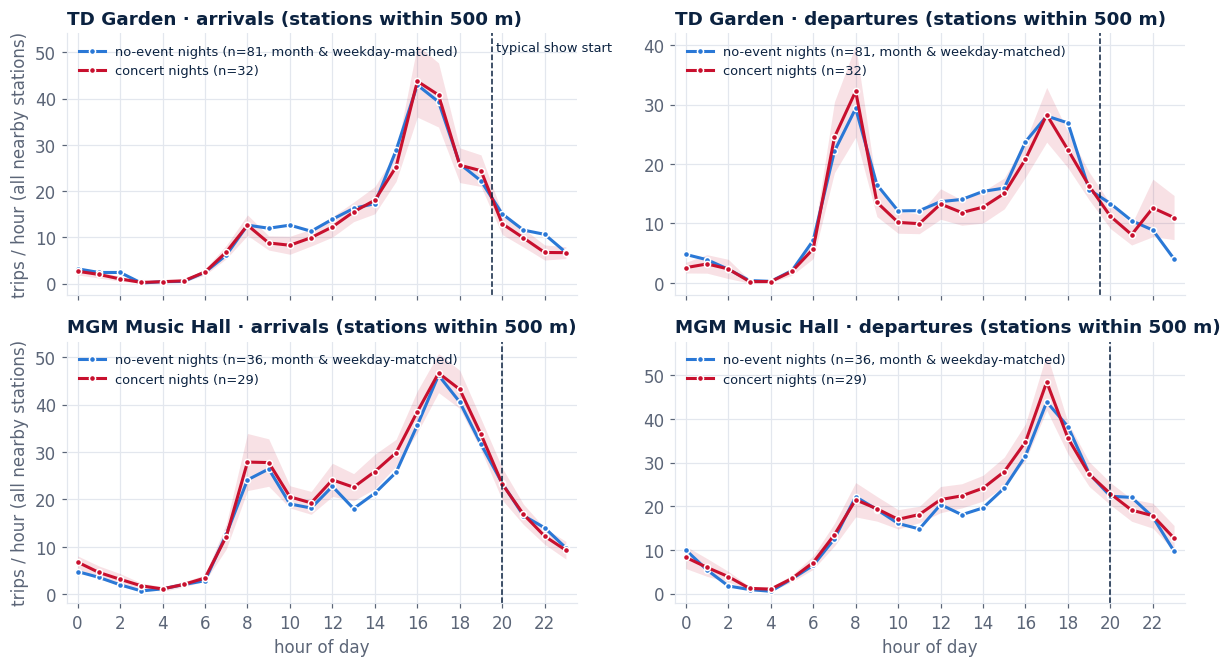

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.2), sharex=True)
hours = np.arange(24)
for r, key in enumerate(["td_garden", "mgm_music_hall"]):
    cfg = setup[key]
    for c, kind in enumerate(["arrivals", "departures"]):
        ax = axes[r, c]
        mean, se, base = results[(key, kind)]
        ax.fill_between(hours, mean - 1.96 * se, mean + 1.96 * se, color=EVENT, alpha=0.12, linewidth=0)
        ax.plot(hours, base, color=BASE, linewidth=2, marker="o", markersize=4, markeredgecolor="white", label=f"no-event nights (n={len(cfg['none'])}, month & weekday-matched)")
        ax.plot(hours, mean, color=EVENT, linewidth=2, marker="o", markersize=4, markeredgecolor="white", label=f"concert nights (n={len(cfg['concert'])})")
        ax.axvline(cfg["median_start"], color=NAVY, linestyle="--", linewidth=1)
        ax.set_title(f"{cfg['label']} · {kind} (stations within 500 m)")
        ax.set_xticks(range(0, 24, 2))
        ax.set_xlim(-0.5, 23.5)
        if c == 0: ax.set_ylabel("trips / hour (all nearby stations)")
        ax.legend(fontsize=8.5, loc="upper left")
for ax in axes[1]: ax.set_xlabel("hour of day")
axes[0, 0].text(setup["td_garden"]["median_start"] + 0.2, axes[0, 0].get_ylim()[1] * 0.93, "typical show start", fontsize=8.5, color=NAVY)
fig.tight_layout()
fig.savefig(FIG / "fig_concert_nights_demand.png")
plt.show()

## Slide figure: departures only

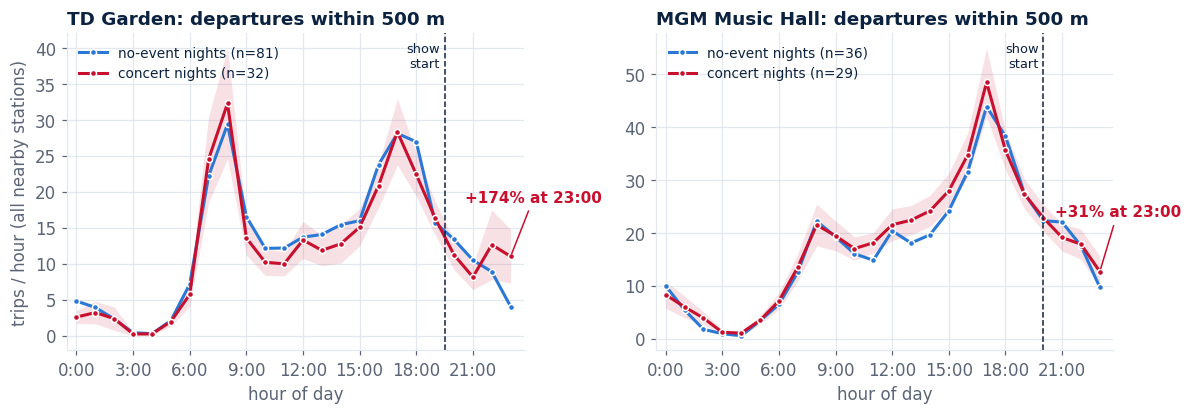

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharey=False)
for ax, key in zip(axes, ["td_garden", "mgm_music_hall"]):
    cfg = setup[key]
    mean, se, base = results[(key, "departures")]
    ax.fill_between(hours, mean - 1.96 * se, mean + 1.96 * se, color=EVENT, alpha=0.12, linewidth=0)
    ax.plot(hours, base, color=BASE, linewidth=2, marker="o", markersize=4, markeredgecolor="white", label=f"no-event nights (n={len(cfg['none'])})")
    ax.plot(hours, mean, color=EVENT, linewidth=2, marker="o", markersize=4, markeredgecolor="white", label=f"concert nights (n={len(cfg['concert'])})")
    ax.axvline(cfg["median_start"], color=NAVY, linestyle="--", linewidth=1)
    ax.text(cfg["median_start"] - 0.25, ax.get_ylim()[1] * 0.97, "show\nstart", fontsize=8.5, color=NAVY, ha="right", va="top")
    pct = mean[23] / base[23] - 1
    ax.annotate(f"{pct:+.0%} at 23:00", xy=(23, mean[23]), xytext=(20.6, mean[23] + ax.get_ylim()[1] * 0.18),
                fontsize=10, color=EVENT, weight="bold", arrowprops=dict(arrowstyle="-", color=EVENT, lw=1))
    ax.set_title(f"{cfg['label']}: departures within 500 m")
    ax.set_xticks(range(0, 24, 3), [f"{h}:00" for h in range(0, 24, 3)])
    ax.set_xlim(-0.5, 23.7)
    ax.set_xlabel("hour of day")
    ax.legend(fontsize=9, loc="upper left")
axes[0].set_ylabel("trips / hour (all nearby stations)")
fig.tight_layout()
fig.savefig(FIG / "fig_concert_departures.png")
plt.show()

## Night by night: how much does each concert add after the show?
The averages above hide how different individual nights are. Here each night is one dot:
**post-show departures (22:00–02:00) minus a typical night** in the same month and weekday type.

- **Service day:** trips are assigned to a 4 am–4 am day, so a 12:30 am departure counts for the concert night.
- **Grey dots:** no-event nights, compared with the other no-event nights in their group (leave-one-out). This shows ordinary night-to-night noise.

In [6]:
SHIFT = pd.Timedelta(hours=4)
POST = [22, 23, 0, 1]
service_days = [d for d in days if d < pd.Timestamp("2024-10-31").date()]  # Oct 31 needs Nov 1 early hours
cell = lambda d: (d.month, 0 if d.weekday() < 4 else 1 if d.weekday() < 6 else 2)
nights = {}
for key, cfg in setup.items():
    x = trips[trips.start_station_name.isin(cfg["stations"])]
    x = x.assign(day=(x.started_at - SHIFT).dt.date, hour=x.started_at.dt.hour)
    post = x[x.hour.isin(POST)].groupby("day").size()
    con = [d for d in cfg["concert"] if d in service_days]
    non = [d for d in cfg["none"] if d in service_days]
    ref = pd.DataFrame({"day": non, "n": [post.get(d, 0) for d in non], "cell": [cell(d) for d in non]})
    def typical(d, exclude=None):
        r = ref[(ref.cell == cell(d)) & (ref.day != exclude)]
        if r.empty: r = ref[(ref.cell.map(lambda c: c[0]) == d.month) & (ref.day != exclude)]
        return r.n.mean()
    names = events[events.venue_key == key].assign(d=lambda e: pd.to_datetime(e.date_start).dt.date).set_index("d").event_name
    con_df = pd.DataFrame({"day": con, "n": [post.get(d, 0) for d in con]})
    con_df["typical"] = [typical(d) for d in con]
    con_df["extra"] = con_df.n - con_df.typical
    con_df["event"] = [names.get(d) for d in con]
    ref["typical"] = [typical(d, exclude=d) for d in ref.day]
    ref["extra"] = ref.n - ref.typical
    sd = ref.extra.std()
    nights[key] = dict(con=con_df.sort_values("extra", ascending=False), ref=ref, sd=sd)
    print(f"{cfg['label']}: {len(con_df)} concert nights | no-event noise SD {sd:.1f} | "
          f"concert nights > +2 SD: {(con_df.extra > 2 * sd).sum()} | mean extra {con_df.extra.mean():+.1f} per night")
    display(nights[key]["con"].head(5).round(1))

MGM Music Hall: 29 concert nights | no-event noise SD 24.4 | concert nights > +2 SD: 0 | mean extra +8.5 per night


,day,n,typical,extra,event
27,2024-10-25,74,31.3,42.7,Lee Brice
13,2024-08-31,92,52.0,40.0,Goth Babe
6,2024-06-07,82,46.0,36.0,Gary Clark Jr.
11,2024-08-08,52,26.4,25.6,YOASOBI
10,2024-08-03,76,52.0,24.0,Cheap Trick


TD Garden: 31 concert nights | no-event noise SD 8.3 | concert nights > +2 SD: 8 | mean extra +10.1 per night


,day,n,typical,extra,event
21,2024-09-16,70,10.8,59.2,Hans Zimmer
22,2024-09-17,68,10.8,57.2,Kygo
30,2024-10-17,56,10.2,45.8,Maggie Rogers
13,2024-08-13,48,11.6,36.4,Future & Metro Boomin
29,2024-09-28,66,33.0,33.0,Charli XCX & Troye Sivan


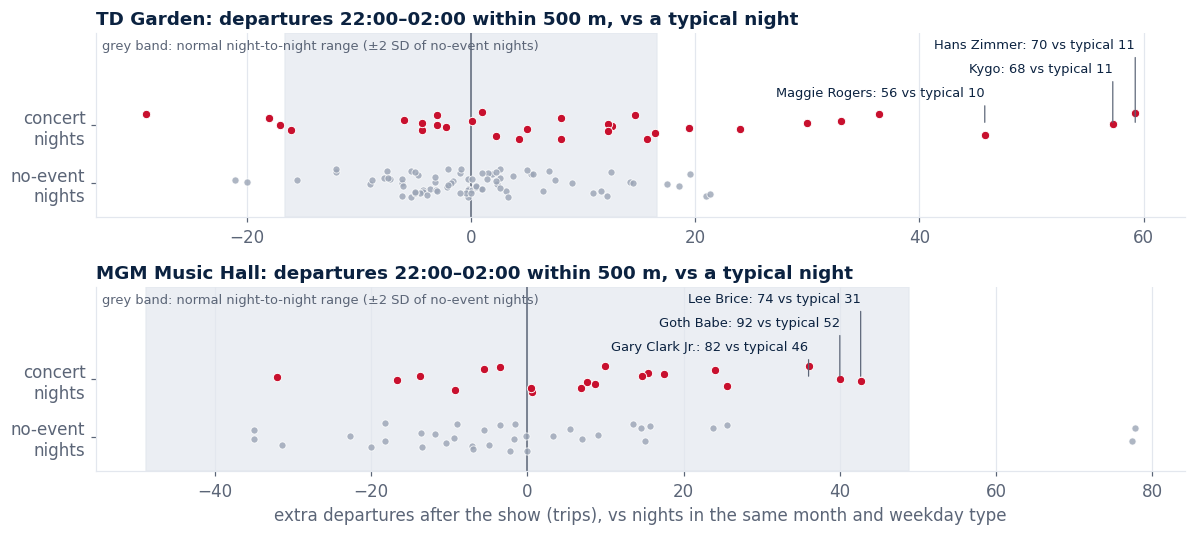

In [7]:
rng = np.random.default_rng(7)
fig, axes = plt.subplots(2, 1, figsize=(11, 5.0), sharex=False)
for ax, key in zip(axes, ["td_garden", "mgm_music_hall"]):
    cfg, nt = setup[key], nights[key]
    sd = nt["sd"]
    ax.axvspan(-2 * sd, 2 * sd, color=GRID, alpha=0.7, zorder=0)
    ax.axvline(0, color=MUTED, linewidth=1, zorder=1)
    ax.scatter(nt["ref"].extra, rng.uniform(-0.25, 0.25, len(nt["ref"])) + 0, s=22, color="#9aa4b5", alpha=0.8, edgecolor="white", linewidth=0.6, zorder=2, label=f"no-event nights (n={len(nt['ref'])})")
    ax.scatter(nt["con"].extra, rng.uniform(-0.25, 0.25, len(nt["con"])) + 1, s=30, color=EVENT, edgecolor="white", linewidth=0.6, zorder=3, label=f"concert nights (n={len(nt['con'])})")
    top = nt["con"].head(3).sort_values("extra")
    for i, (_, r) in enumerate(top.iterrows()):
        ax.annotate(f"{r.event}: {r.n:.0f} vs typical {r.typical:.0f}", xy=(r.extra, 1), xytext=(r.extra, 1.5 + 0.42 * i),
                    ha="right", fontsize=8.5, color=NAVY, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8, relpos=(1, 0.5)))
    ax.set_yticks([0, 1], ["no-event\nnights", "concert\nnights"])
    ax.set_ylim(-0.6, 2.6)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"{cfg['label']}: departures 22:00–02:00 within 500 m, vs a typical night")
    ax.text(0.005, 0.97, "grey band: normal night-to-night range (±2 SD of no-event nights)", transform=ax.transAxes, fontsize=8.5, color=MUTED, va="top")
axes[-1].set_xlabel("extra departures after the show (trips), vs nights in the same month and weekday type")
fig.tight_layout()
fig.savefig(FIG / "fig_concert_nights_strip.png")
plt.show()

## Slide figure: TD Garden, the evening and each night

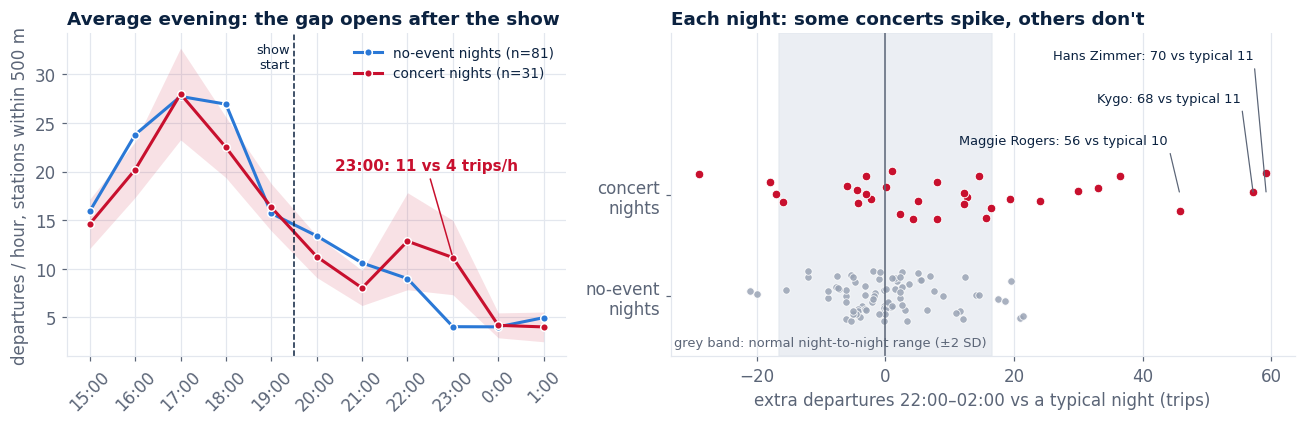

23:00 concert 11.2 vs no-event 4.1; nights > +2 SD: 8 of 31; top ratio 6.5x


In [8]:
key, cfg, nt = "td_garden", setup["td_garden"], nights["td_garden"]
order = [15, 16, 17, 18, 19, 20, 21, 22, 23, 0, 1]          # 3 pm to 2 am on the service day
x = trips[trips.start_station_name.isin(cfg["stations"])]
x = x.assign(day=(x.started_at - SHIFT).dt.date, hour=x.started_at.dt.hour)
m = x.groupby(["day", "hour"]).size().unstack(fill_value=0).reindex(columns=range(24), fill_value=0)
con = [d for d in cfg["concert"] if d in service_days]; non = [d for d in cfg["none"] if d in service_days]
C, N = m.reindex(con, fill_value=0), m.reindex(non, fill_value=0)
w = pd.Series([cell(d) for d in con]).value_counts(normalize=True)
cn = pd.Series([cell(d) for d in non], index=non); w = w[w.index.isin(set(cn))]; w = w / w.sum()
base = sum(N[(cn == k).values].mean() * wt for k, wt in w.items())
mean, se = C.mean(), C.std(ddof=1) / np.sqrt(len(C))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.0), gridspec_kw={"width_ratios": [1, 1.25]})
xs = np.arange(len(order))
a1.fill_between(xs, (mean - 1.96 * se)[order], (mean + 1.96 * se)[order], color=EVENT, alpha=0.12, linewidth=0)
a1.plot(xs, base[order], color=BASE, lw=2, marker="o", ms=5, mec="white", label=f"no-event nights (n={len(non)})")
a1.plot(xs, mean[order], color=EVENT, lw=2, marker="o", ms=5, mec="white", label=f"concert nights (n={len(con)})")
start_x = order.index(19) + 0.5
a1.axvline(start_x, color=NAVY, ls="--", lw=1)
a1.text(start_x - 0.1, a1.get_ylim()[1] * 0.97, "show\nstart", ha="right", va="top", fontsize=8.5, color=NAVY)
pk = order.index(23)
a1.annotate(f"23:00: {mean[23]:.0f} vs {base[23]:.0f} trips/h", xy=(pk, mean[23]), xytext=(pk - 2.6, mean[23] + 9),
            fontsize=10, color=EVENT, weight="bold", arrowprops=dict(arrowstyle="-", color=EVENT, lw=1))
a1.set_xticks(xs, [f"{h}:00" for h in order], rotation=45)
a1.set_ylabel("departures / hour, stations within 500 m")
a1.set_title("Average evening: the gap opens after the show")
a1.legend(fontsize=9, loc="upper right")

sd = nt["sd"]
a2.axvspan(-2 * sd, 2 * sd, color=GRID, alpha=0.7, zorder=0)
a2.axvline(0, color=MUTED, lw=1)
rng = np.random.default_rng(7)
a2.scatter(nt["ref"].extra, rng.uniform(-0.25, 0.25, len(nt["ref"])), s=24, color="#9aa4b5", alpha=0.85, edgecolor="white", lw=0.6, label=f"no-event nights (n={len(nt['ref'])})")
a2.scatter(nt["con"].extra, rng.uniform(-0.25, 0.25, len(nt["con"])) + 1, s=32, color=EVENT, edgecolor="white", lw=0.6, label=f"concert nights (n={len(nt['con'])})")
top = nt["con"].head(3).sort_values("extra")
for i, (_, r) in enumerate(top.iterrows()):
    a2.annotate(f"{r.event}: {r.n:.0f} vs typical {r.typical:.0f}", xy=(r.extra, 1), xytext=(r.extra - 2, 1.5 + 0.42 * i),
                ha="right", fontsize=8.5, color=NAVY, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8, relpos=(1, 0.5)))
a2.set_yticks([0, 1], ["no-event\nnights", "concert\nnights"])
a2.set_ylim(-0.6, 2.6)
a2.grid(axis="y", visible=False)
a2.set_xlabel("extra departures 22:00–02:00 vs a typical night (trips)")
a2.set_title("Each night: some concerts spike, others don't")
a2.text(0.005, 0.03, "grey band: normal night-to-night range (±2 SD)", transform=a2.transAxes, fontsize=8.5, color=MUTED)
fig.tight_layout()
fig.savefig(FIG / "fig_td_garden_concerts.png")
plt.show()
print(f"23:00 concert {mean[23]:.1f} vs no-event {base[23]:.1f}; nights > +2 SD: {(nt['con'].extra > 2 * sd).sum()} of {len(nt['con'])}; "
      f"top ratio {(nt['con'].n / nt['con'].typical).max():.1f}x")

## Headline numbers

In [9]:
def ratio(venue, kind, h): return summary.query("venue == @venue and kind == @kind and hour == @h").iloc[0]
rows = []
for venue in ["TD Garden", "MGM Music Hall"]:
    for kind, h in [("departures", 22), ("departures", 23), ("arrivals", 18), ("arrivals", 19)]:
        x = ratio(venue, kind, h)
        rows.append({"venue": venue, "measure": f"{kind} {h}:00", "concert": x.concert, "no_event": x.no_event,
                     "change": f"{(x.ratio - 1):+.0%}", "beyond 1.96 SE": x.beyond_2se})
pd.DataFrame(rows)

,venue,measure,concert,no_event,change,beyond 1.96 SE
0,TD Garden,departures 22:00,12.6,8.9,+42%,False
1,TD Garden,departures 23:00,11.0,4.0,+174%,True
2,TD Garden,arrivals 18:00,25.6,25.9,-1%,False
3,TD Garden,arrivals 19:00,24.4,22.2,+10%,False
4,MGM Music Hall,departures 22:00,17.9,17.6,+2%,False
5,MGM Music Hall,departures 23:00,12.7,9.7,+31%,True
6,MGM Music Hall,arrivals 18:00,43.2,40.6,+7%,False
7,MGM Music Hall,arrivals 19:00,33.8,31.7,+7%,False


## Findings
- **Clean comparison groups matter.** A weekday-only match left MGM concert days higher *all day* (a seasonal effect). Matching on month and weekday type fixed that. Removing nights with *other* events at the same stations (Fenway Park concerts, House of Blues, Big Night Live, Do617-listed events) fixed a second problem: some "no-event" nights were not quiet. The biggest MGM "concert" spike (Pretenders, 19 Jul 2024) fell on a Fenway Park stadium-concert night.
- **TD Garden: a clear post-show effect.** At 23:00, departures are **11 vs 4 trips/h** on clean concert nights. 8 of 31 concert nights are more than 2 SD above a typical night; the biggest (Hans Zimmer, Kygo, Maggie Rogers) bring **5–6× the usual** 22:00–02:00 departures, while many concert nights look like ordinary nights.
- **MGM: no clear effect.** No clean concert night stands out from normal night-to-night variation in the busy Kenmore/BU area (5,000-seat venue).
- **Arrivals before shows barely change** at either venue.
- **Implication for the study:** event impact varies a lot from show to show. A model needs to tell big nights from quiet ones, which is what event features (capacity, timing) and possibly text must do.
- **Caveats:** one season (May–Oct 2024), no weather adjustment, small samples after cleaning (TD 31–32 nights, MGM 29), and smaller events we can't see may remain.